# Final Hard Thresholding training on Fritz

Train Hard Thresholding on the full training set with the selected rank and iteration count, then evaluate it once on the test set.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from evaluation import mae_from_predictions, rmse_from_predictions
from hard_thresholding_hpc import (
    hard_thresholding_model_matrix_free,
    predict_pairs,
)

## Load the processed data

In [2]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "ml-latest"
RESULTS_DIR = PROJECT_ROOT / "results" / "hard_thresholding_final"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(PROCESSED_DIR / "train_ratings.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_ratings.csv")
user_map = pd.read_csv(PROCESSED_DIR / "user_map.csv")
movie_map = pd.read_csv(PROCESSED_DIR / "movie_map.csv")

n_users = len(user_map)
n_movies = len(movie_map)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Number of users:", n_users)
print("Number of movies:", n_movies)

Train shape: (27065729, 6)
Test shape: (6766433, 6)
Number of users: 330975
Number of movies: 83239


## Selected hyperparameters

In [3]:
best_hard_rank = 12
best_hard_n_iter = 450
hard_svd_tol = 1e-4
hard_svd_maxiter = 300

print("Final Hard Thresholding rank:", best_hard_rank)
print("Final Hard Thresholding iterations:", best_hard_n_iter)

Final Hard Thresholding rank: 12
Final Hard Thresholding iterations: 450


## Retrain on the full training set

In [4]:
# Compile the Numba prediction kernel before the full training run.
predict_pairs(
    np.ones((2, 1)),
    np.ones(1),
    np.ones((2, 1)),
    np.array([0], dtype=np.int64),
    np.array([0], dtype=np.int64),
)

U_hard, singular_values_hard, V_hard, hard_history = (
    hard_thresholding_model_matrix_free(
        train_df,
        n_users=n_users,
        n_movies=n_movies,
        rank=best_hard_rank,
        n_iter=best_hard_n_iter,
        svd_tol=hard_svd_tol,
        svd_maxiter=hard_svd_maxiter,
        random_state=42,
    )
)
hard_history.to_csv(RESULTS_DIR / "training_history.csv", index=False)

## Test-set evaluation

In [5]:
test_user_idx = test_df["user_idx"].to_numpy(dtype=np.int64)
test_movie_idx = test_df["movie_idx"].to_numpy(dtype=np.int64)
test_ratings = test_df["rating"].to_numpy(dtype=np.float64)

hard_test_predictions = predict_pairs(
    U_hard,
    singular_values_hard,
    V_hard,
    test_user_idx,
    test_movie_idx,
)
hard_test_predictions = np.clip(hard_test_predictions, 0.5, 5.0)
hard_test_rmse = rmse_from_predictions(test_ratings, hard_test_predictions)
hard_test_mae = mae_from_predictions(test_ratings, hard_test_predictions)

test_metrics_df = pd.DataFrame([{
    "rank": best_hard_rank,
    "n_iter": best_hard_n_iter,
    "test_rmse": hard_test_rmse,
    "test_mae": hard_test_mae,
}])
test_metrics_df.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
display(test_metrics_df)

,rank,n_iter,test_rmse,test_mae
0,12,450,0.799608,0.59856


## Training history

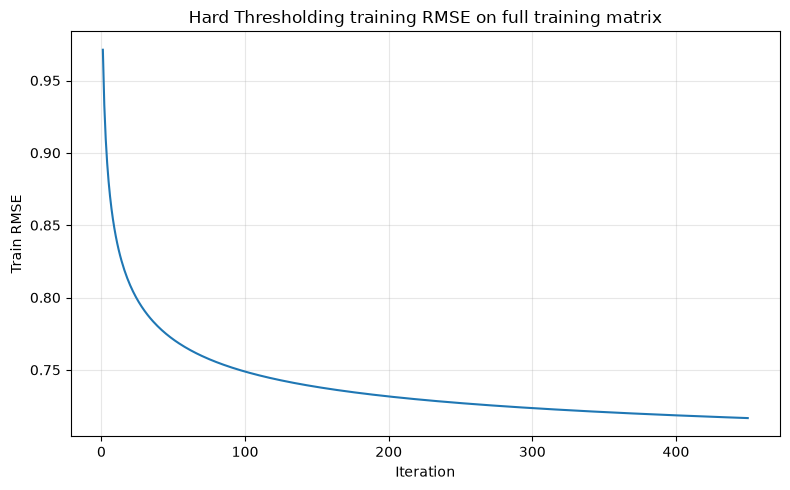

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(
    hard_history["iteration"],
    hard_history["train_rmse"],
)
plt.title("Hard Thresholding training RMSE on full training matrix")
plt.xlabel("Iteration")
plt.ylabel("Train RMSE")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()